# Projeto final: surrogate neural para aerofólios

- rede que recebe os 12 CST, alpha e log10 Re e devolve cl, log10 cd e cm
- a ideia é substituir o XFOIL na previsão dos coeficientes
- a NACA 2412 fica fora do treino, validação e teste e só entra no final

## Configuração

- no Colab monta o Drive e lê a pasta `Data Driven`
- fora do Colab procura a pasta `airfoil_db_v1_to_students` ao lado do script ou uma pasta acima
- dá pra trocar o caminho com a variável `DB`

In [1]:
import copy
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DB = Path('/content/drive/MyDrive/Data Driven')
except ImportError:
    try:
        AQUI = Path(__file__).resolve().parent
    except NameError:                       # rodando como notebook
        AQUI = Path.cwd()
    pasta = next((p for p in (AQUI, AQUI.parent) if (p / 'airfoil_db_v1_to_students').exists()), AQUI)
    DB = Path(os.environ.get('DB', pasta / 'airfoil_db_v1_to_students'))

torch.manual_seed(0)

## Dados e divisão

- as duas tabelas se ligam pelo `id`
- log10 de Re (entrada) e de Cd (saída)
- a NACA 2412 sai da base antes de tudo, e depois fica só espessura de 6% a 16%
- o split é por aerofólio (70/15/15), senão pontos do mesmo aerofólio ficam em conjuntos diferentes e o teste fica bom demais
- os aerofólios sintéticos são perturbações dos reais, então um sintético de teste pode ter o original no treino. O enunciado só pede separar por `id`, então fiz assim

In [2]:
airfoils = pd.read_csv(DB / 'airfoils.csv')
polars = pd.read_csv(DB / 'polars.csv')

# une pelo id
uni = pd.merge(polars, airfoils, on='id')

# log de Re e Cd
uni['LogRe'] = np.log10(uni['Re'])
uni['LogCd'] = np.log10(uni['Cd'])

# naca2412 vira o alvo e sai da base, depois filtra a espessura
target = uni[uni['name'] == 'naca2412']
assert len(target) > 0, 'naca2412 não está no airfoils.csv'
uni = uni[uni['name'] != 'naca2412']
uni = uni[(uni['t_max'] >= 0.06) & (uni['t_max'] <= 0.16)]

# split por aerofólio (todos os pontos de um id no mesmo conjunto)
rng = np.random.default_rng(30)
ids = rng.permutation(uni['id'].unique())

n = len(ids)
n_tr = int(n * 0.7)
n_v = int(n * 0.15)

ids_tr = ids[:n_tr]                  # primeiros 70%
ids_val = ids[n_tr:n_tr + n_v]       # de 70% a 85%
ids_te = ids[n_tr + n_v:]            # de 85% a 100%

treino = uni[uni['id'].isin(ids_tr)]
val = uni[uni['id'].isin(ids_val)]
teste = uni[uni['id'].isin(ids_te)]

print('Aerofólios treino/val/teste:', len(ids_tr), len(ids_val), len(ids_te))
print('Pontos treino/val/teste:', len(treino), len(val), len(teste))

Aerofólios treino/val/teste: 2171 465 466
Pontos treino/val/teste: 141697 30427 30163


## Preparação

- X tem 14 colunas (12 CST, alpha e log10 Re) e Y tem 3 (cl, log10 cd, cm)
- média e desvio só do treino, aplicados nos outros conjuntos (inclusive a NACA 2412)

In [3]:
X_columns = ['Au0', 'Au1', 'Au2', 'Au3', 'Au4', 'Au5',
             'Al0', 'Al1', 'Al2', 'Al3', 'Al4', 'Al5', 'alpha', 'LogRe']
Y_columns = ['Cl', 'LogCd', 'Cm']


def X_Y(df):
    X = df[X_columns].values.astype(np.float32)
    Y = df[Y_columns].values.astype(np.float32)
    return X, Y


def padroniza(X, Y, mx, sx, my, sy):
    return (X - mx) / sx, (Y - my) / sy


# estatísticas só do treino
X_tr, Y_tr = X_Y(treino)
mx_tr, sx_tr = X_tr.mean(axis=0), X_tr.std(axis=0)
my_tr, sy_tr = Y_tr.mean(axis=0), Y_tr.std(axis=0)
assert np.all(sx_tr > 0) and np.all(sy_tr > 0), 'coluna constante no treino'

X_tr, Y_tr = padroniza(X_tr, Y_tr, mx_tr, sx_tr, my_tr, sy_tr)
X_val, Y_val = padroniza(*X_Y(val), mx_tr, sx_tr, my_tr, sy_tr)
X_teste, Y_teste = padroniza(*X_Y(teste), mx_tr, sx_tr, my_tr, sy_tr)
X_target, Y_target = padroniza(*X_Y(target), mx_tr, sx_tr, my_tr, sy_tr)

# tensores
Entrada_treino, Saida_treino = torch.tensor(X_tr), torch.tensor(Y_tr)
Entrada_val, Saida_val = torch.tensor(X_val), torch.tensor(Y_val)
Entrada_teste = torch.tensor(X_teste)
Entrada_target = torch.tensor(X_target)

## Rede e treino

- 2 camadas ocultas de 64 neurônios com tanh e saída linear
- MSE, Adam e mini-lotes de 256
- early stopping: se a validação não melhora por 20 épocas, para e volta aos pesos da melhor época

In [4]:
def treina(rede, X, Y, Xv, Yv, lr=1e-3, batch=256, paciencia=20, max_epocas=500):
    # Adam + MSE + early stopping, devolve históricos, melhor época e melhor erro de validação
    loss_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(rede.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, Y), batch_size=batch, shuffle=True)

    melhor_val = float('inf')        # melhor erro até agora
    contador = 0                     # épocas seguidas sem melhorar
    melhores_pesos = None
    hist_treino, hist_val = [], []

    for epoca in range(max_epocas):
        soma = 0
        for xb, yb in loader:
            loss = loss_fn(rede(xb), yb)
            otimizador.zero_grad()
            loss.backward()
            otimizador.step()
            soma += loss.item()
        hist_treino.append(soma / len(loader))

        with torch.no_grad():
            loss_val = loss_fn(rede(Xv), Yv).item()
        hist_val.append(loss_val)

        if loss_val < melhor_val:
            melhor_val = loss_val
            melhores_pesos = copy.deepcopy(rede.state_dict())
            contador = 0
        else:
            contador += 1
            if contador >= paciencia:
                print('Parou na época', epoca + 1)
                break

    rede.load_state_dict(melhores_pesos)
    return hist_treino, hist_val, int(np.argmin(hist_val)) + 1, melhor_val


rede = nn.Sequential(
    nn.Linear(14, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 3)     # saída linear: Cl, LogCd e Cm
)

hist_treino, hist_val, melhor_epoca, melhor_val = treina(
    rede, Entrada_treino, Saida_treino, Entrada_val, Saida_val)
print('Melhor época:', melhor_epoca, '| erro de validação:', melhor_val)

Parou na época 156
Melhor época: 136 | erro de validação: 0.0037160541396588087


### Erros no teste

- RMSE de cl e cm em unidades reais
- no cd volto do log com `10**x` e calculo o erro relativo médio em %

In [5]:
with torch.no_grad():
    prev_teste = rede(Entrada_teste).numpy()          # padronizada

prev_teste_real = prev_teste * sy_tr + my_tr
Y_teste_real = Y_teste * sy_tr + my_tr

rmse_cl = np.sqrt(np.mean((prev_teste_real[:, 0] - Y_teste_real[:, 0]) ** 2))
rmse_cm = np.sqrt(np.mean((prev_teste_real[:, 2] - Y_teste_real[:, 2]) ** 2))
cd_prev = 10 ** prev_teste_real[:, 1]
cd_real = 10 ** Y_teste_real[:, 1]
erro_cd = np.mean(np.abs(cd_prev - cd_real) / cd_real) * 100

print('RMSE cl:', rmse_cl)
print('RMSE cm:', rmse_cm)
print('Erro médio cd (%):', erro_cd)

RMSE cl: 0.01269211
RMSE cm: 0.0020130964
Erro médio cd (%): 1.3021804


### NACA 2412 (nunca vista)

- rede contra XFOIL nos 4 Reynolds: curva de sustentação, polar de arrasto e momento

NACA 2412: RMSE cl = 0.0037 | erro cd = 0.48 %


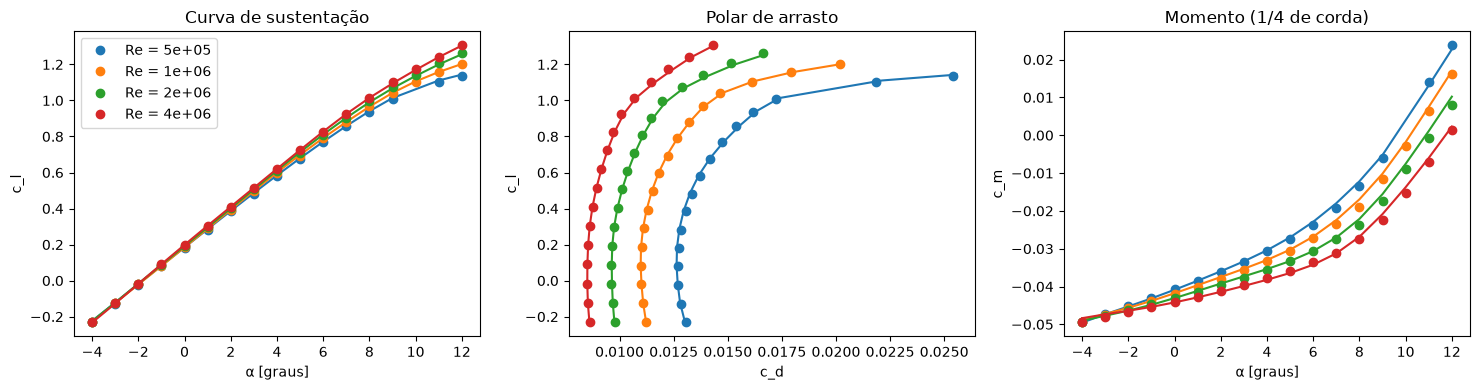

In [6]:
with torch.no_grad():
    prev_target = rede(Entrada_target).numpy()

alpha_na = target['alpha'].values
Re_na = target['Re'].values
prev_target_real = prev_target * sy_tr + my_tr
Y_target_real = Y_target * sy_tr + my_tr

rmse_cl_na = np.sqrt(np.mean((prev_target_real[:, 0] - Y_target_real[:, 0]) ** 2))
erro_cd_na = np.mean(np.abs(10 ** prev_target_real[:, 1] - 10 ** Y_target_real[:, 1])
                     / 10 ** Y_target_real[:, 1]) * 100
print(f'NACA 2412: RMSE cl = {rmse_cl_na:.4f} | erro cd = {erro_cd_na:.2f} %')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for Re_val in np.unique(Re_na):
    m = (Re_na == Re_val)
    ordem = np.argsort(alpha_na[m])          # ordena por alpha

    a = alpha_na[m][ordem]
    cl_x, cl_r = Y_target_real[m, 0][ordem], prev_target_real[m, 0][ordem]
    cm_x, cm_r = Y_target_real[m, 2][ordem], prev_target_real[m, 2][ordem]
    cd_x, cd_r = 10 ** Y_target_real[m, 1][ordem], 10 ** prev_target_real[m, 1][ordem]

    p = ax[0].plot(a, cl_x, 'o', label=f'Re = {Re_val:.0e}')
    cor = p[0].get_color()                   # mesma cor pro XFOIL e pra rede
    ax[0].plot(a, cl_r, '-', color=cor)
    ax[1].plot(cd_x, cl_x, 'o', color=cor)
    ax[1].plot(cd_r, cl_r, '-', color=cor)
    ax[2].plot(a, cm_x, 'o', color=cor)
    ax[2].plot(a, cm_r, '-', color=cor)

ax[0].set_xlabel('α [graus]'); ax[0].set_ylabel('c_l'); ax[0].set_title('Curva de sustentação')
ax[1].set_xlabel('c_d');       ax[1].set_ylabel('c_l'); ax[1].set_title('Polar de arrasto')
ax[2].set_xlabel('α [graus]'); ax[2].set_ylabel('c_m'); ax[2].set_title('Momento (1/4 de corda)')
ax[0].legend()
plt.tight_layout()
plt.show()

### Inclinação de cl e centro aerodinâmico

- faixa linear (|alpha| <= 4 graus), ajusto uma reta
- a inclinação sai em 1/grau, então multiplico por 180/pi pra ter 1/rad
- x_ac = 0,25 - dcm/dcl, e dcm/dcl é a inclinação de cm contra cl

In [7]:
for Re_val in np.unique(Re_na):
    m = (Re_na == Re_val)
    a = alpha_na[m]
    cl_x, cl_r = Y_target_real[m, 0], prev_target_real[m, 0]
    cm_x, cm_r = Y_target_real[m, 2], prev_target_real[m, 2]
    lin = np.abs(a) <= 4

    dcm_x = np.polyfit(cl_x[lin], cm_x[lin], 1)[0]
    dcm_r = np.polyfit(cl_r[lin], cm_r[lin], 1)[0]
    cla_x = np.polyfit(a[lin], cl_x[lin], 1)[0] * 180 / np.pi
    cla_r = np.polyfit(a[lin], cl_r[lin], 1)[0] * 180 / np.pi
    xac_x, xac_r = 0.25 - dcm_x, 0.25 - dcm_r

    print(f'Re = {Re_val:.0e} | c_lα XFOIL = {cla_x:.3f} | rede = {cla_r:.3f} '
          f'| diferença = {abs(cla_r - cla_x) / cla_x * 100:.2f} %')
    print(f'Re = {Re_val:.0e} | x_ac XFOIL = {xac_x:.4f} | rede = {xac_r:.4f}')

Re = 5e+05 | c_lα XFOIL = 5.821 | rede = 5.800 | diferença = 0.36 %
Re = 5e+05 | x_ac XFOIL = 0.2275 | rede = 0.2267
Re = 1e+06 | c_lα XFOIL = 5.926 | rede = 5.937 | diferença = 0.18 %
Re = 1e+06 | x_ac XFOIL = 0.2309 | rede = 0.2307
Re = 2e+06 | c_lα XFOIL = 6.020 | rede = 5.998 | diferença = 0.36 %
Re = 2e+06 | x_ac XFOIL = 0.2339 | rede = 0.2335
Re = 4e+06 | c_lα XFOIL = 6.103 | rede = 6.121 | diferença = 0.29 %
Re = 4e+06 | x_ac XFOIL = 0.2366 | rede = 0.2382


### Curvas de aprendizado

- erro de treino e validação por época (escala log), com a melhor época marcada
- as duas curvas caem rápido nas primeiras épocas e depois melhoram devagar
- a validação fica um pouco acima do treino (são formas que a rede não viu), mas a diferença é pequena e não cresce, então quase não tem sobreajuste
- o treino parou na época 156 e os pesos guardados são da época 136

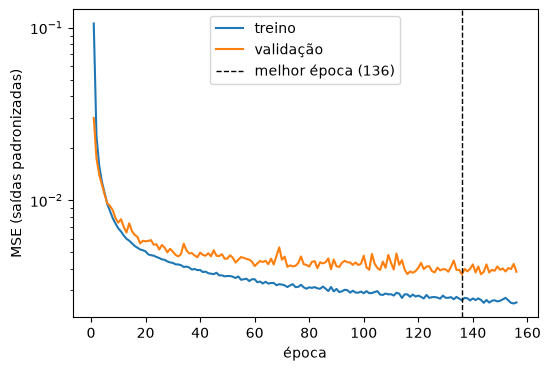

In [8]:
def grafico_MSExepoca(hist_treino, hist_val, melhor_epoca):
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(hist_treino) + 1), hist_treino, label='treino')
    plt.plot(range(1, len(hist_val) + 1), hist_val, label='validação')
    plt.axvline(melhor_epoca, color='k', ls='--', lw=1, label=f'melhor época ({melhor_epoca})')
    plt.yscale('log')
    plt.xlabel('época'); plt.ylabel('MSE (saídas padronizadas)'); plt.legend()
    plt.show()


grafico_MSExepoca(hist_treino, hist_val, melhor_epoca)

## Fontes

### Bibliotecas

- PyTorch, montar a rede (nn.Sequential): <https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html>
- PyTorch, otimizador Adam: <https://pytorch.org/docs/stable/generated/torch.optim.Adam.html>
- PyTorch, DataLoader e TensorDataset: <https://pytorch.org/docs/stable/data.html>
- PyTorch, tutorial de como montar uma rede: <https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html>
- NumPy, ajuste de reta (np.polyfit): <https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html>
- pandas, juntar tabelas (pd.merge): <https://pandas.pydata.org/docs/reference/api/pandas.merge.html>
- matplotlib, gráficos (plt.subplots): <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html>

### Dados e ferramentas

- XFOIL: <https://web.mit.edu/drela/Public/web/xfoil/>
- UIUC Airfoil Coordinates Database: <https://m-selig.ae.illinois.edu/ads/coord_database.html>
- base da disciplina: README da pasta airfoil_db_v1_to_students

### Métodos

- Adam: Kingma e Ba (2014): <https://arxiv.org/abs/1412.6980>
- early stopping: Goodfellow et al., Deep Learning, cap. 7: <https://www.deeplearningbook.org/>
- coeficientes CST: Kulfan (2008), Universal Parametric Geometry Representation Method, Journal of Aircraft